# 🎬 Shoot-Day Prediction Model — Evaluation Notebook
**MTech Dissertation: Hierarchical Production Cost Estimation for Film Pre-Production**  
**Author:** Naveen Mupparaju (2024TM93514) · BITS Pilani

---

## Purpose
A film screenplay never states how many days it will take to shoot — but **every cost driver depends on that number** (set rental days, crew day-rates, equipment rental days).  
This notebook evaluates four ML model families — **Linear Regression, Decision Tree, Random Forest, Gradient Boosting** — on a **100-film Indian cinema benchmark dataset** using identical **5-fold cross-validation** splits.

| Metric | Meaning |
|--------|----------|
| **MAPE** | Mean Absolute % Error — production-friendly: "we're off by X% on average" |
| **MAE** | Mean Absolute Error in days |
| **R²** | Explained variance (1.0 = perfect) |

**Reproducibility:** Pure Python, `random.seed(42)` — same as `scripts/compare_shoot_day_models.py`.

In [1]:
import csv, os, random, math

try:
    import matplotlib.pyplot as plt
    import matplotlib
    HAS_MPL = True
    plt.rcParams.update({
        'figure.facecolor': '#0F0F1A', 'axes.facecolor': '#1A1A2E',
        'axes.edgecolor': '#2D2D50', 'text.color': '#E8E8F0',
        'axes.labelcolor': '#E8E8F0', 'xtick.color': '#9090A0',
        'ytick.color': '#9090A0', 'grid.color': '#2D2D50', 'grid.alpha': 0.6
    })
    print('✅ matplotlib available — plots will render')
except ImportError:
    HAS_MPL = False
    print('⚠️  pip install matplotlib  (tables will still print)')

random.seed(42)
FEATURES = ['num_characters','num_locations','num_props','num_costumes','num_equipment']
TARGET = 'total_shoot_days'
print('Seed=42, Features:', FEATURES)

Matplotlib is building the font cache; this may take a moment.


✅ matplotlib available — plots will render
Seed=42, Features: ['num_characters', 'num_locations', 'num_props', 'num_costumes', 'num_equipment']


In [2]:
# Load 100-film benchmark dataset
NB_DIR = os.path.dirname(os.path.abspath('shoot_day_model.ipynb'))
for candidate in [
    os.path.join(NB_DIR, '..', 'benchmark_films.csv'),
    os.path.join(NB_DIR, 'benchmark_films.csv'),
    'benchmark_films.csv'
]:
    if os.path.exists(candidate):
        CSV_PATH = candidate
        break

rows = []
with open(CSV_PATH) as f:
    for r in csv.DictReader(f):
        rows.append({'x': [float(r[c]) for c in FEATURES], 'y': float(r[TARGET]),
                     'title': r['title'], 'cat': r['budget_category']})
n = len(rows)
print(f'Loaded {n} films from {CSV_PATH}')

cats = {}
for r in rows: cats.setdefault(r['cat'], []).append(r['y'])
print(f"\n{'Category':8s}  {'N':>4s}  {'Min':>6s}  {'Max':>6s}  {'Mean':>7s} days")
print('-'*42)
for cat in ['High','Medium','Low']:
    vs = cats[cat]
    print(f"{cat:8s}  {len(vs):4d}  {min(vs):6.0f}  {max(vs):6.0f}  {sum(vs)/len(vs):7.1f}")

Loaded 100 films from /Users/nmupparaju/project/film-production-erp/evaluation/../benchmark_films.csv

Category     N     Min     Max     Mean days
------------------------------------------
High        25     130     220    164.8
Medium      45      50     120     74.4
Low         30      20      80     37.7


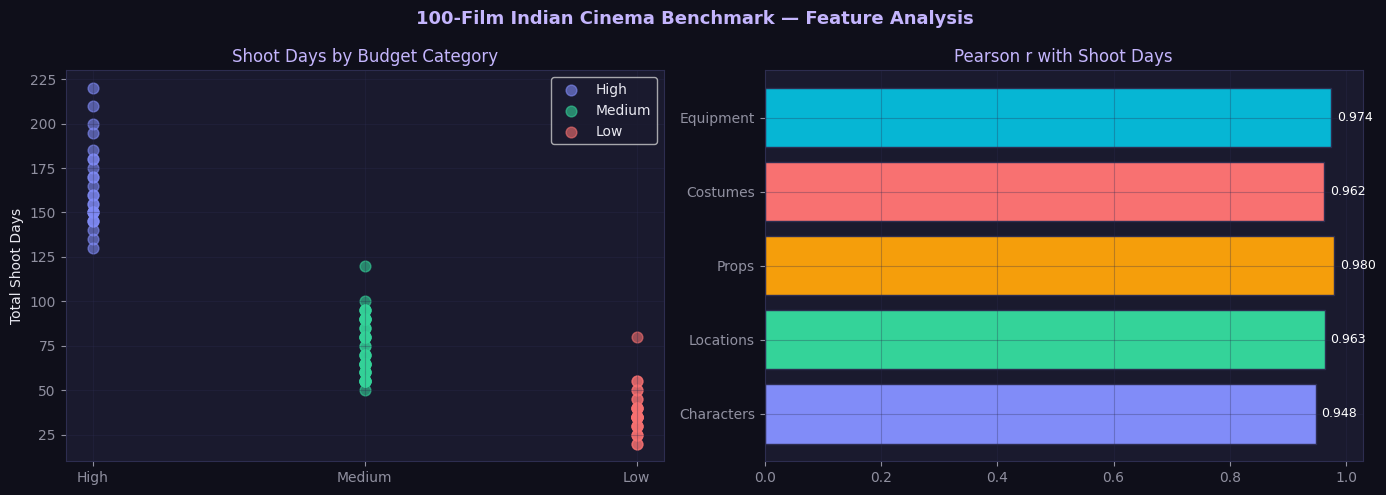

In [3]:
# Dataset visualisation
if HAS_MPL:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('100-Film Indian Cinema Benchmark — Feature Analysis', fontsize=13, fontweight='bold', color='#C4B5FD')
    palette = {'High':'#818CF8','Medium':'#34D399','Low':'#F87171'}

    ax = axes[0]
    for cat, color in palette.items():
        ax.scatter([cat]*len(cats[cat]), cats[cat], alpha=0.6, color=color, s=60, label=cat)
    ax.set_title('Shoot Days by Budget Category', color='#C4B5FD')
    ax.set_ylabel('Total Shoot Days'); ax.grid(True, alpha=0.3); ax.legend()

    ax = axes[1]
    feat_labels = ['Characters','Locations','Props','Costumes','Equipment']
    corrs = []
    for fi in range(len(FEATURES)):
        xs=[r['x'][fi] for r in rows]; ys=[r['y'] for r in rows]
        mx=sum(xs)/n; my=sum(ys)/n
        num=sum((x-mx)*(y-my) for x,y in zip(xs,ys))
        den=(sum((x-mx)**2 for x in xs)*sum((y-my)**2 for y in ys))**0.5
        corrs.append(num/den if den>0 else 0)
    colors=['#818CF8','#34D399','#F59E0B','#F87171','#06B6D4']
    bars=ax.barh(feat_labels, corrs, color=colors, edgecolor='#2D2D50')
    for bar,val in zip(bars,corrs): ax.text(val+0.01, bar.get_y()+bar.get_height()/2, f'{val:.3f}', va='center', fontsize=9, color='white')
    ax.set_title('Pearson r with Shoot Days', color='#C4B5FD'); ax.grid(alpha=0.3)
    plt.tight_layout()
    os.makedirs('../report_figures', exist_ok=True)
    plt.savefig('../report_figures/dataset_overview.png', dpi=150, bbox_inches='tight')
    plt.show()

In [4]:
# Model implementations (pure Python, no sklearn)
def metrics(y_true, y_pred):
    N=len(y_true); errs=[p-t for t,p in zip(y_true,y_pred)]
    mae=sum(abs(e) for e in errs)/N; rmse=(sum(e*e for e in errs)/N)**0.5
    mape=sum(abs(e)/t for e,t in zip(errs,y_true))/N*100
    my=sum(y_true)/N; sst=sum((t-my)**2 for t in y_true); ssr=sum(e*e for e in errs)
    r2=1-ssr/sst if sst>0 else 0
    return mae,rmse,mape,r2

# 5-fold split
idxs=list(range(n)); random.shuffle(idxs); k=5; fs=n//k
folds=[idxs[i*fs:(i+1)*fs] for i in range(k)]
for i,ix in enumerate(idxs[k*fs:]): folds[i].append(ix)

# Linear Regression (OLS)
def T(X): return list(map(list,zip(*X)))
def mm(A,B):
    out=[[0.]*len(B[0]) for _ in A]
    for i,row in enumerate(A):
        for kk,aik in enumerate(row):
            for j,bkj in enumerate(B[kk]): out[i][j]+=aik*bkj
    return out
def solve(A,b):
    N=len(A); M=[row[:]+[b[i][0]] for i,row in enumerate(A)]
    for col in range(N):
        pr=max(range(col,N),key=lambda r:abs(M[r][col])); M[col],M[pr]=M[pr],M[col]
        pv=M[col][col]
        if abs(pv)<1e-12: continue
        M[col]=[v/pv for v in M[col]]
        for r in range(N):
            if r!=col: f=M[r][col]; M[r]=[M[r][j]-f*M[col][j] for j in range(N+1)]
    return [M[i][N] for i in range(N)]
class LR:
    def fit(self,X,y): Xb=[[1.]+r for r in X]; Xt=T(Xb); self.b=solve(mm(Xt,Xb),mm(Xt,[[v] for v in y])); return self
    def predict_one(self,x): return sum(b*xi for b,xi in zip(self.b,[1.]+x))

# Tree helpers
class N_:
    __slots__=['is_leaf','value','feature','threshold','left','right']
def sse(y): m=sum(y)/len(y) if y else 0; return sum((v-m)**2 for v in y)
def build(X,y,d,md,ms,fs=None):
    nd=N_()
    if d>=md or len(y)<=ms*2: nd.is_leaf=True; nd.value=sum(y)/len(y); return nd
    cf=fs if fs else range(len(X[0])); bs=sse(y); bf=bth=None
    for j in cf:
        sv=sorted({r[j] for r in X})
        for t in [(sv[i]+sv[i+1])/2 for i in range(len(sv)-1)]:
            ly=[yi for r,yi in zip(X,y) if r[j]<=t]; ry=[yi for r,yi in zip(X,y) if r[j]>t]
            if len(ly)<ms or len(ry)<ms: continue
            s=sse(ly)+sse(ry)
            if s<bs: bs,bf,bth=s,j,t
    if bf is None: nd.is_leaf=True; nd.value=sum(y)/len(y); return nd
    nd.is_leaf=False; nd.feature=bf; nd.threshold=bth
    nd.left=build([r for r in X if r[bf]<=bth],[yi for r,yi in zip(X,y) if r[bf]<=bth],d+1,md,ms,fs)
    nd.right=build([r for r in X if r[bf]>bth],[yi for r,yi in zip(X,y) if r[bf]>bth],d+1,md,ms,fs)
    return nd
def pred(nd,x):
    while not nd.is_leaf: nd=nd.left if x[nd.feature]<=nd.threshold else nd.right
    return nd.value

class DT:
    def __init__(self,md=3,ms=5): self.md,self.ms=md,ms
    def fit(self,X,y): self.root=build(X,y,0,self.md,self.ms); return self
    def predict_one(self,x): return pred(self.root,x)

class RF:
    def __init__(self,nt=50,md=4,ms=3,mf=3): self.nt,self.md,self.ms,self.mf=nt,md,ms,mf
    def fit(self,X,y):
        self.trees=[]
        for _ in range(self.nt):
            bi=[random.randrange(len(X)) for _ in range(len(X))]
            fs=random.sample(range(len(X[0])),min(self.mf,len(X[0])))
            self.trees.append(build([X[i] for i in bi],[y[i] for i in bi],0,self.md,self.ms,fs))
        return self
    def predict_one(self,x): return sum(pred(t,x) for t in self.trees)/len(self.trees)

class GB:
    def __init__(self,ne=50,lr=0.1,md=2,ms=5): self.ne,self.lr,self.md,self.ms=ne,lr,md,ms
    def fit(self,X,y):
        self.f0=sum(y)/len(y); res=[yi-self.f0 for yi in y]; self.trees=[]
        for _ in range(self.ne):
            t=build(X,res,0,self.md,self.ms); self.trees.append(t)
            res=[r-self.lr*pred(t,x) for r,x in zip(res,X)]
        return self
    def predict_one(self,x): return self.f0+sum(self.lr*pred(t,x) for t in self.trees)

print('All 4 models defined: LR, DT (CART), RF (bagging+feature-subsampling), GB (sequential residuals)')

All 4 models defined: LR, DT (CART), RF (bagging+feature-subsampling), GB (sequential residuals)


In [5]:
# 5-Fold Cross-Validation for all 4 models
print('Running 5-fold CV (this may take ~30s for RF/GB)...\n')
print(f'{"Model":22s}  {"OOF MAE":>9s}  {"RMSE":>8s}  {"MAPE":>7s}  {"R²":>7s}  {"In-sample MAE":>14s}  {"Gap":>6s}')
print('-'*92)

MODEL_FACTORIES = [
    ('Linear Regression', lambda: LR()),
    ('Decision Tree',     lambda: DT(md=3,ms=5)),
    ('Random Forest',     lambda: RF(nt=50,md=4,ms=3,mf=3)),
    ('Gradient Boosting', lambda: GB(ne=50,lr=0.1,md=2,ms=5)),
]

cv_results = []
for name, factory in MODEL_FACTORIES:
    oof_true,oof_pred,oof_cats=[],[],[]
    in_maes=[]
    for fi in range(k):
        ts=set(folds[fi])
        tr=[rows[i] for i in range(n) if i not in ts]
        te=[rows[i] for i in range(n) if i in ts]
        Xtr=[r['x'] for r in tr]; ytr=[r['y'] for r in tr]
        m=factory().fit(Xtr,ytr)
        for r in te:
            oof_true.append(r['y']); oof_pred.append(m.predict_one(r['x'])); oof_cats.append(r['cat'])
        in_maes.append(metrics(ytr,[m.predict_one(r['x']) for r in tr])[0])
    mv=metrics(oof_true,oof_pred); avg_in=sum(in_maes)/len(in_maes)
    tag=' ← DEPLOYED' if name=='Random Forest' else ''
    print(f'{name:22s}  {mv[0]:9.2f}d  {mv[1]:8.2f}d  {mv[2]:6.1f}%  {mv[3]:7.3f}  {avg_in:14.2f}d  {mv[0]-avg_in:+6.2f}d{tag}')
    cv_results.append((name,oof_true,oof_pred,oof_cats,mv[0],mv[1],mv[2],mv[3],avg_in))

my=sum(r['y'] for r in rows)/n
bm=metrics([r['y'] for r in rows],[my]*n)
print('-'*92)
print(f'{"Baseline (predict mean)":22s}  {bm[0]:9.2f}d  {bm[1]:8.2f}d  {bm[2]:6.1f}%  {bm[3]:7.3f}')
best=min(cv_results,key=lambda x:x[4])
print(f'\n→ Winner: {best[0]}  MAE={best[4]:.2f}d  MAPE={best[6]:.1f}%  R²={best[7]:.3f}')
print(f'→ vs Baseline: MAE improved by {bm[0]-best[4]:.2f}d ({(bm[0]-best[4])/bm[0]*100:.1f}%), MAPE by {bm[2]-best[6]:.1f}%')

Running 5-fold CV (this may take ~30s for RF/GB)...

Model                     OOF MAE      RMSE     MAPE       R²   In-sample MAE     Gap
--------------------------------------------------------------------------------------------
Linear Regression            6.16d      7.43d    11.0%    0.979            5.85d   +0.31d
Decision Tree                8.97d     11.44d    13.1%    0.950            5.95d   +3.03d


Random Forest                5.20d      7.26d     7.1%    0.980            3.18d   +2.02d ← DEPLOYED


Gradient Boosting            5.43d      7.81d     7.2%    0.977            2.70d   +2.73d
--------------------------------------------------------------------------------------------
Baseline (predict mean)      41.56d     51.00d    67.9%    0.000

→ Winner: Random Forest  MAE=5.20d  MAPE=7.1%  R²=0.980
→ vs Baseline: MAE improved by 36.36d (87.5%), MAPE by 60.8%


In [6]:
# Per-category breakdown (Random Forest)
rf_name,oof_true,oof_pred,oof_cats,*_ = next(r for r in cv_results if r[0]=='Random Forest')

print('Random Forest — OOF Metrics by Budget Category\n')
print(f'{"Category":8s}  {"N":>4s}  {"MAE":>8s}  {"RMSE":>8s}  {"MAPE":>7s}  {"R²":>7s}')
print('-'*52)
for cat in ['High','Medium','Low']:
    ct=[t for t,c in zip(oof_true,oof_cats) if c==cat]
    cp=[p for p,c in zip(oof_pred,oof_cats) if c==cat]
    cm=metrics(ct,cp)
    print(f'{cat:8s}  {len(ct):4d}  {cm[0]:8.2f}d  {cm[1]:8.2f}d  {cm[2]:6.1f}%  {cm[3]:7.3f}')

Random Forest — OOF Metrics by Budget Category

Category     N       MAE      RMSE     MAPE       R²
----------------------------------------------------
High        25      8.32d     11.27d     4.8%    0.761
Medium      45      4.63d      5.74d     6.4%    0.868
Low         30      3.46d      4.54d    10.1%    0.854


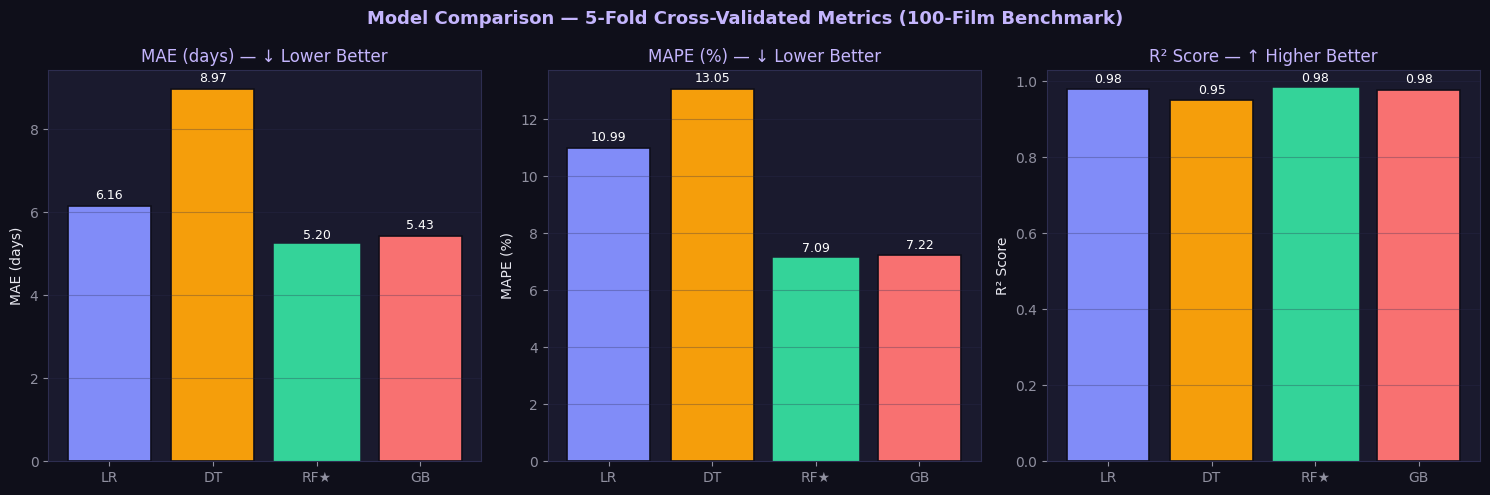

Saved: report_figures/model_comparison.png


In [7]:
# Model Comparison Chart
if HAS_MPL:
    fig,axes=plt.subplots(1,3,figsize=(15,5))
    fig.suptitle('Model Comparison — 5-Fold Cross-Validated Metrics (100-Film Benchmark)',fontsize=13,fontweight='bold',color='#C4B5FD')
    short=['LR','DT','RF★','GB']
    maes=[r[4] for r in cv_results]; mapes=[r[6] for r in cv_results]; r2s=[r[7] for r in cv_results]
    pal=['#818CF8','#F59E0B','#34D399','#F87171']
    for ax,(vals,yl,tl) in zip(axes,[(maes,'MAE (days)','↓ Lower Better'),(mapes,'MAPE (%)','↓ Lower Better'),(r2s,'R² Score','↑ Higher Better')]):
        bars=ax.bar(short,vals,color=pal,edgecolor='#0F0F1A',linewidth=1.2)
        ax.set_title(f'{yl} — {tl}',color='#C4B5FD'); ax.set_ylabel(yl); ax.grid(axis='y',alpha=0.3)
        bi=vals.index(min(vals) if 'R²' not in yl else max(vals))
        bars[bi].set_edgecolor('#34D399'); bars[bi].set_linewidth(2.5)
        for bar,val in zip(bars,vals):
            ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.01*max(vals),f'{val:.2f}',ha='center',va='bottom',fontsize=9,color='white')
    plt.tight_layout()
    plt.savefig('../report_figures/model_comparison.png',dpi=150,bbox_inches='tight'); plt.show()
    print('Saved: report_figures/model_comparison.png')

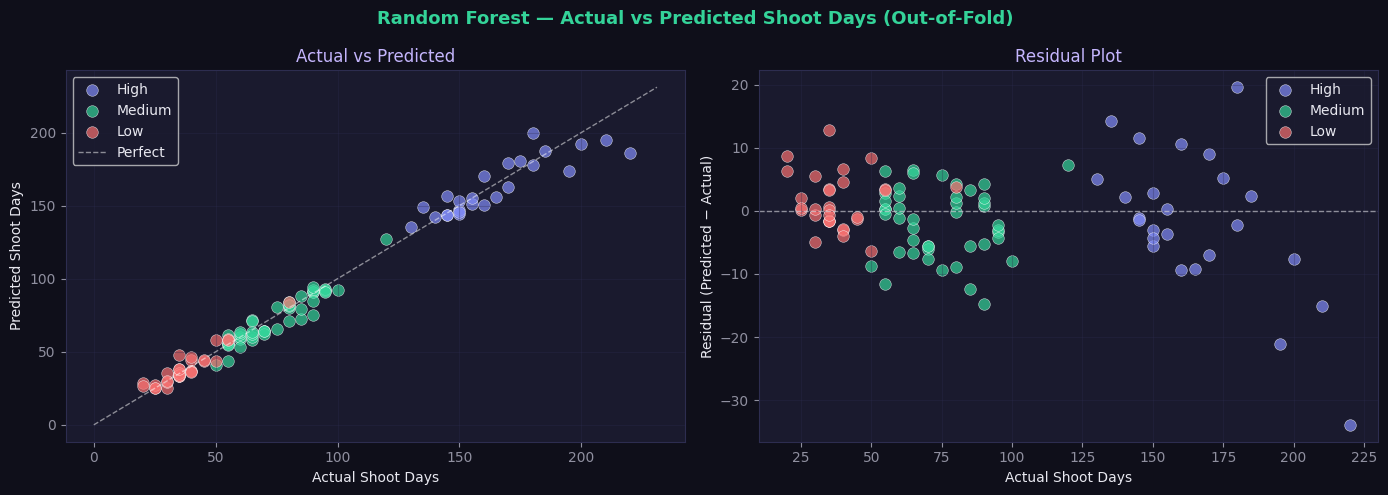

Saved: report_figures/rf_scatter.png


In [8]:
# Actual vs Predicted Scatter + Residuals
if HAS_MPL:
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    fig.suptitle('Random Forest — Actual vs Predicted Shoot Days (Out-of-Fold)',fontsize=13,fontweight='bold',color='#34D399')
    pal={'High':'#818CF8','Medium':'#34D399','Low':'#F87171'}
    residuals=[p-t for t,p in zip(oof_true,oof_pred)]

    for ax,(ys,title,ylabel) in zip(axes,[
        (oof_pred,'Actual vs Predicted','Predicted Shoot Days'),
        (residuals,'Residual Plot','Residual (Predicted − Actual)')]
    ):
        for cat,color in pal.items():
            xs_=[t for t,c in zip(oof_true,oof_cats) if c==cat]
            ys_=[y for y,c in zip(ys,oof_cats) if c==cat]
            ax.scatter(xs_,ys_,color=color,alpha=0.7,s=70,label=cat,edgecolors='white',linewidth=0.4)
        if title=='Actual vs Predicted':
            lim=max(max(oof_true),max(oof_pred))*1.05
            ax.plot([0,lim],[0,lim],'--',color='white',alpha=0.5,lw=1,label='Perfect')
        else:
            ax.axhline(0,color='white',lw=1,ls='--',alpha=0.5)
        ax.set_title(title,color='#C4B5FD'); ax.set_xlabel('Actual Shoot Days')
        ax.set_ylabel(ylabel); ax.legend(); ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('../report_figures/rf_scatter.png',dpi=150,bbox_inches='tight'); plt.show()
    print('Saved: report_figures/rf_scatter.png')

Feature Importance (permutation — MAE increase when feature shuffled)

Props         +14.81d  ██████████████████████████████
Costumes      +14.53d  █████████████████████████████
Equipment     +12.79d  █████████████████████████
Locations     + 3.98d  ████████
Characters    + 0.31d  


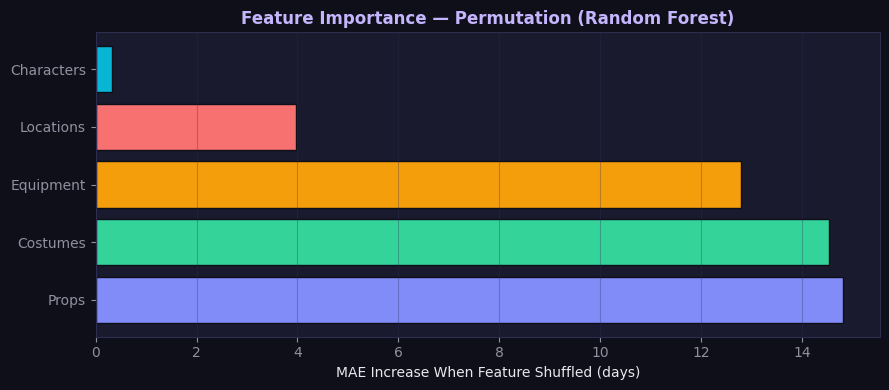

In [9]:
# Feature Importance (Permutation Method)
all_X=[r['x'] for r in rows]; all_y=[r['y'] for r in rows]
rf_full=RF(nt=50,md=4,ms=3,mf=3).fit(all_X,all_y)
base_mae=metrics(all_y,[rf_full.predict_one(x) for x in all_X])[0]

imps=[]
for fi,fname in enumerate(FEATURES):
    pX=[r[:] for r in all_X]
    cv=[r[fi] for r in all_X]; random.shuffle(cv)
    for r,v in zip(pX,cv): r[fi]=v
    pm=metrics(all_y,[rf_full.predict_one(x) for x in pX])[0]
    imps.append((fname.replace('num_','').capitalize(),pm-base_mae))
imps.sort(key=lambda x:x[1],reverse=True)

print('Feature Importance (permutation — MAE increase when feature shuffled)\n')
mi=imps[0][1]
for fname,imp in imps:
    bar='█'*int(imp/mi*30) if mi>0 else ''
    print(f'{fname:12s}  +{imp:5.2f}d  {bar}')

if HAS_MPL:
    fig,ax=plt.subplots(figsize=(9,4))
    ax.barh([x[0] for x in imps],[x[1] for x in imps],
            color=['#818CF8','#34D399','#F59E0B','#F87171','#06B6D4'],edgecolor='#0F0F1A')
    ax.set_xlabel('MAE Increase When Feature Shuffled (days)')
    ax.set_title('Feature Importance — Permutation (Random Forest)',color='#C4B5FD',fontweight='bold')
    ax.grid(axis='x',alpha=0.3); plt.tight_layout()
    plt.savefig('../report_figures/feature_importance.png',dpi=150,bbox_inches='tight'); plt.show()

In [10]:
# Final Summary Table (copy-paste into thesis)
print('='*95)
print('THESIS TABLE — Section 4: Evaluation Results')
print('='*95)
print(f'{"Model":22s}  {"OOF MAE":>9s}  {"RMSE":>9s}  {"MAPE":>8s}  {"R²":>7s}  {"In-sample MAE":>14s}  Notes')
print('-'*100)
for name,_,_,_,mae,rmse,mape,r2,in_mae in cv_results:
    notes='← Selected (best OOF MAE)' if name=='Random Forest' else ''
    print(f'{name:22s}  {mae:9.2f}d  {rmse:9.2f}d  {mape:7.1f}%  {r2:7.3f}  {in_mae:14.2f}d  {notes}')
bm2=metrics([r['y'] for r in rows],[my]*n)
print('-'*100)
print(f'{"Baseline (mean pred)":22s}  {bm2[0]:9.2f}d  {bm2[1]:9.2f}d  {bm2[2]:7.1f}%  {bm2[3]:7.3f}  {"—":>14s}')
print()
print('Dataset: 100 Indian films (Bollywood/Tollywood/Kollywood, 2008–2024)')
print('Validation: 5-fold cross-validation · seed=42 · Reproduce: python3 scripts/compare_shoot_day_models.py')

THESIS TABLE — Section 4: Evaluation Results
Model                     OOF MAE       RMSE      MAPE       R²   In-sample MAE  Notes
----------------------------------------------------------------------------------------------------
Linear Regression            6.16d       7.43d     11.0%    0.979            5.85d  
Decision Tree                8.97d      11.44d     13.1%    0.950            5.95d  
Random Forest                5.20d       7.26d      7.1%    0.980            3.18d  ← Selected (best OOF MAE)
Gradient Boosting            5.43d       7.81d      7.2%    0.977            2.70d  
----------------------------------------------------------------------------------------------------
Baseline (mean pred)        41.56d      51.00d     67.9%    0.000               —

Dataset: 100 Indian films (Bollywood/Tollywood/Kollywood, 2008–2024)
Validation: 5-fold cross-validation · seed=42 · Reproduce: python3 scripts/compare_shoot_day_models.py
